Predict future averge price of Vegetables and Fruits monthly by using SARIMAX model and Linear Regression Model
* According to the result, SARIMAX is better. But we can't tell exactly because of the causes of Covid 19 and Political changes

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2009-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [12]:
DVFM = data.copy()
DVFM = DVFM[DVFM['category']=='vegetables and fruits']
DVFM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448
5,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,484.85,0.2724
8,1/15/2008,Magway,Magway,Magway,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,181.82,0.1021
13,1/15/2008,Magway,Pakokku,Pakhangyi,vegetables and fruits,Tomatoes,Tomatoes,NaN,KG,actual,Retail,MMK,242.42,0.1362
48,1/15/2008,Shan (North),Hopang,Kaung Ming Sang,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,1190.58,0.6689


In [13]:
DVFM = DVFM[['date', 'price']]
DVFM['date'] = pd.to_datetime(DVFM['date'])
mask = (DVFM['date']>=obv_st_date) & (DVFM['date']<=obv_end_date)
DVFM = DVFM.loc[mask]
DVFM = DVFM.set_index('date')
DVFM.head()

,price
date,
2008-01-15,969.70
2008-01-15,484.85
2008-01-15,181.82
2008-01-15,242.42
2008-01-15,1190.58


In [14]:
DVFM = DVFM.resample('MS').mean()
DVFM.head()

,price
date,
2008-01-01,859.156923
2008-02-01,795.805385
2008-03-01,848.876923
2008-04-01,694.560000
2008-05-01,767.373333


In [15]:
DVFM.shape

(169, 1)

In [16]:
price = DVFM['price']
date = DVFM.index

##### Normalization data

In [17]:
scaler = MinMaxScaler()

In [18]:
DVFM_nor = scaler.fit_transform(DVFM)
DVFM_nor = pd.DataFrame(DVFM_nor)
DVFM_nor.head()

,0
0,0.310563
1,0.262275
2,0.302727
3,0.185104
4,0.240604


In [19]:
DVFM_nor['date']=date
DVFM_nor = DVFM_nor.set_index('date')
DVFM_nor.columns=['price']
DVFM_nor.head()

,price
date,
2008-01-01,0.310563
2008-02-01,0.262275
2008-03-01,0.302727
2008-04-01,0.185104
2008-05-01,0.240604


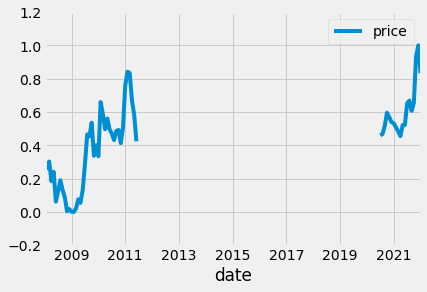

In [20]:
DVFM_nor.plot(grid=True)
plt.show()

There is missing data.

##### Filling data with linear interpolation

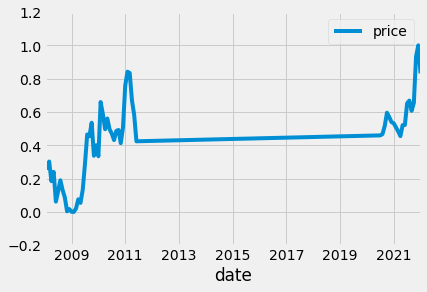

In [21]:
DVFM_nor = DVFM_nor.interpolate(method='linear')
DVFM_nor.plot(grid=True)
plt.show()

There is a like positive trend.

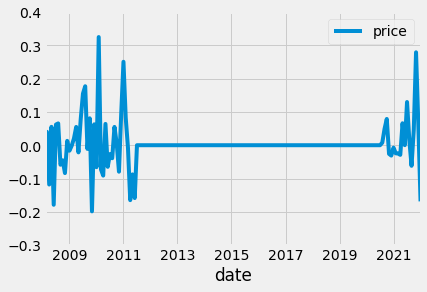

In [22]:
DVFM_nor_diff1 = DVFM_nor.diff(1).dropna()
DVFM_nor_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [23]:
RW_DVFM= adfuller(DVFM_nor_diff1)
RW_DVFM[1] # print P-value. If p-value<5%, reject null hypothesis

8.506435435579e-05

##### Plotting ACF and PACF

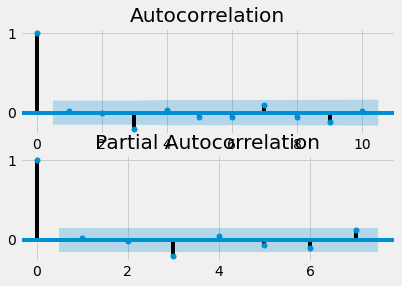

In [24]:
fig, axes=plt.subplots(2,1)
plot_acf(DVFM_nor_diff1, lags=10, ax=axes[0])
plot_pacf(DVFM_nor_diff1, lags=7, ax=axes[1])
plt.show()

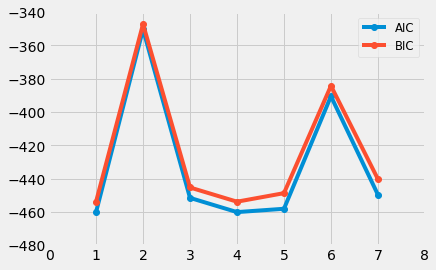

In [25]:
AIC, BIC = AIC_BIC_withOrderRange(DVFM_nor_diff1, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [26]:
AIC, BIC

(array([-461.99473383, -460.07695219, -350.37818514, -451.54709307,
        -460.07640847, -458.07689197, -390.54707514, -449.64746706]),
 array([-458.87076985, -453.82902423, -347.26019133, -445.31110544,
        -453.82848051, -448.70500004, -384.31108751, -440.29348562]))

We will run again 1:(0,0,1), 4:(1,0,0), 5:(1,0,1)

In [27]:
mod_orders = [
    (0,0,1),
    (1,0,0),
    (1,0,1)
]

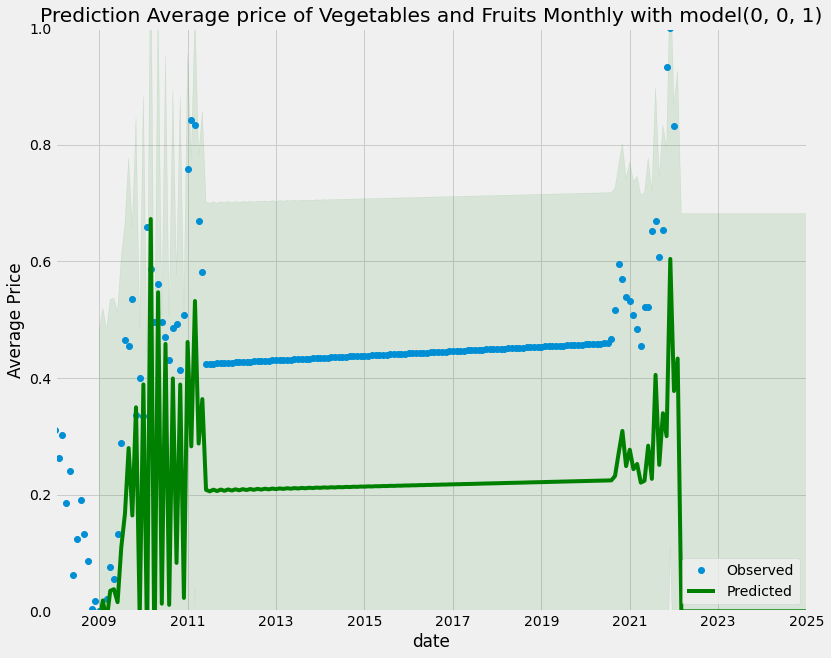

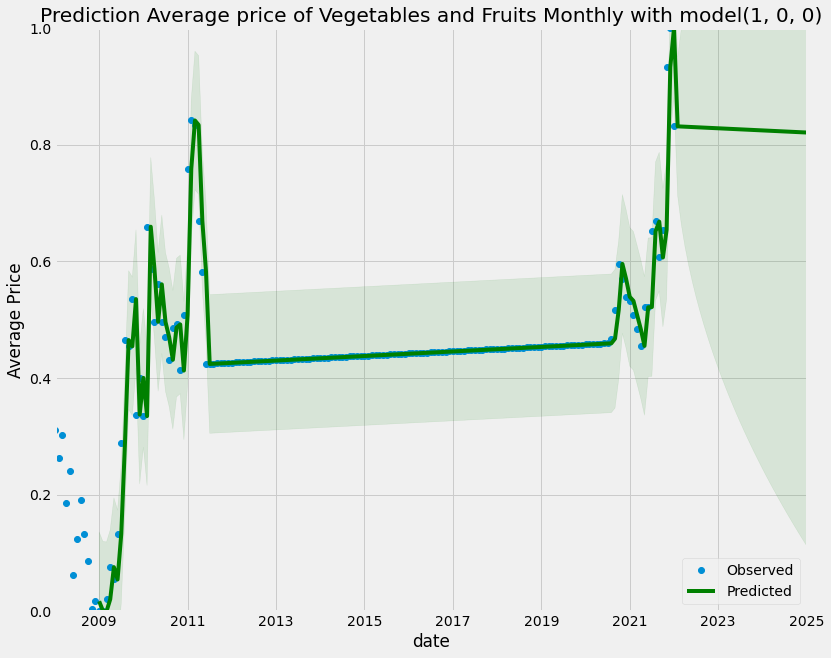

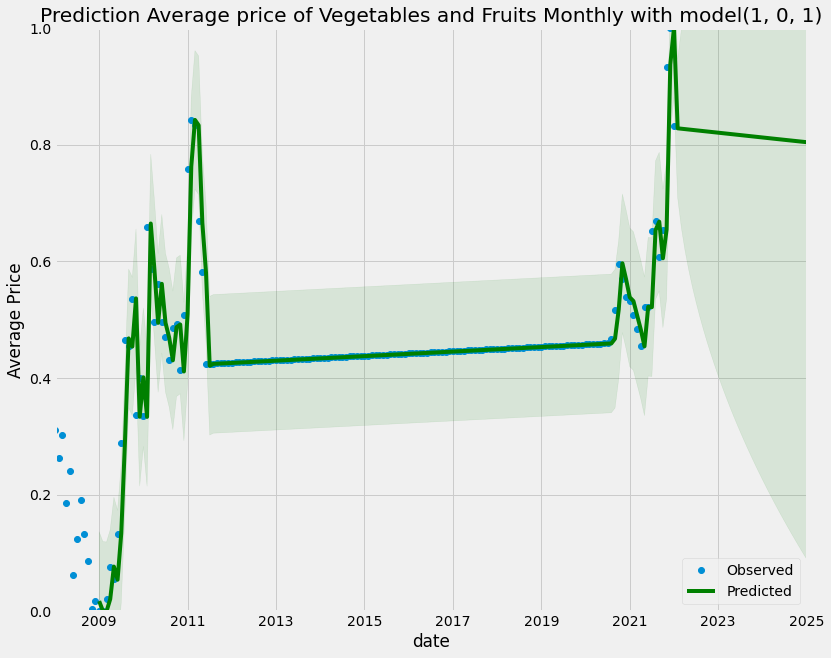

In [28]:
DVFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DVFM_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Vegetables and Fruits Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DVFM_models.append(model)

Now we choose (1,0,0)

In [29]:
DVFM_model = DVFM_models[1]

In [30]:
DVFM_pred_normalized = DVFM_model.predict(pred_st_date, pred_end_date)
DVFM_pred_normalized 

2009-01-01    1.719819e-02
2009-02-01    1.133326e-03
2009-03-01   -1.127564e-19
2009-04-01    2.065842e-02
2009-05-01    7.576120e-02
                  ...     
2024-09-01    8.221499e-01
2024-10-01    8.218488e-01
2024-11-01    8.215478e-01
2024-12-01    8.212468e-01
2025-01-01    8.209460e-01
Freq: MS, Length: 193, dtype: float64

In [31]:
mask = (DVFM_nor.index>=pred_st_date) & (DVFM_nor.index<=pred_end_date)
DVFM_pred = DVFM_nor.loc[mask]
DVFM_pred

,price
date,
2009-01-01,0.001134
2009-02-01,0.000000
2009-03-01,0.020666
2009-04-01,0.075789
2009-05-01,0.054627
...,...
2021-09-01,0.606927
2021-10-01,0.654314
2021-11-01,0.933446


We need to un-normalized the predicted value to get actual price

In [32]:
pred_date = DVFM_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2009-01-01', '2009-02-01', '2009-03-01', '2009-04-01',
               '2009-05-01', '2009-06-01', '2009-07-01', '2009-08-01',
               '2009-09-01', '2009-10-01',
               ...
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01',
               '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', length=192, freq='MS')

In [33]:
DVFM_pred_normalized_df = pd.DataFrame(DVFM_pred_normalized)
DVFM_pred_normalized_df = DVFM_pred_normalized_df[:-1] # the last index doesn't need
DVFM_pred_normalized_df

,0
2009-01-01,1.719819e-02
2009-02-01,1.133326e-03
2009-03-01,-1.127564e-19
2009-04-01,2.065842e-02
2009-05-01,7.576120e-02
...,...
2024-08-01,8.224512e-01
2024-09-01,8.221499e-01
2024-10-01,8.218488e-01
2024-11-01,8.215478e-01


##### Un-normalization data

In [34]:
DVFM_pred_act = scaler.inverse_transform(DVFM_pred_normalized_df)
DVFM_pred_act_df = pd.DataFrame(DVFM_pred_act)
DVFM_pred_act_df['date'] = pred_date
DVFM_pred_act_df.columns = ['Predicted Price', 'date']
DVFM_pred_act_df.set_index('date',  inplace=True)
DVFM_pred_act_df

,Predicted Price
date,
2009-01-01,474.274890
2009-02-01,453.198455
2009-03-01,451.711579
2009-04-01,478.814569
2009-05-01,551.107109
...,...
2024-08-01,1530.733164
2024-09-01,1530.337936
2024-10-01,1529.942852


In [35]:
mask = (DVFM.index>=pred_st_date) & (DVFM.index<=pred_end_date)
DVFM_Act = DVFM.loc[mask]
DVFM_Act

,price
date,
2009-01-01,453.199000
2009-02-01,451.711579
2009-03-01,478.824500
2009-04-01,551.143529
2009-05-01,523.380000
...,...
2021-09-01,1247.974311
2021-10-01,1310.143678
2021-11-01,1676.353356


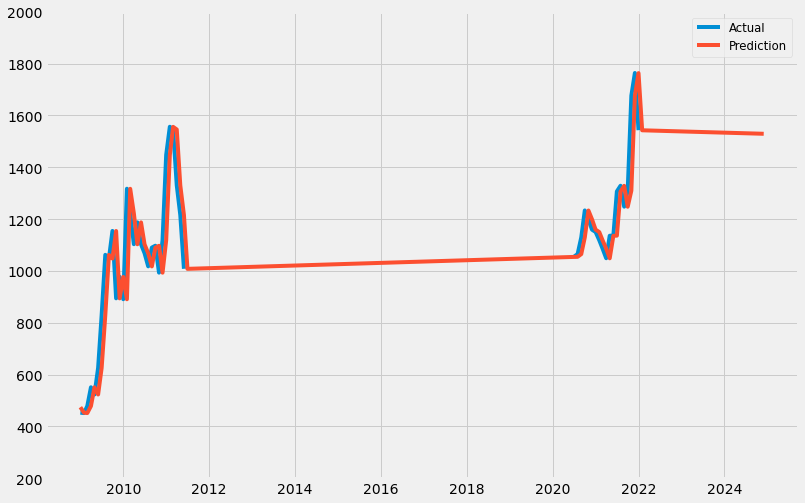

In [36]:
plt.figure(figsize=(12,8))
plt.plot(DVFM_Act, label="Actual")
plt.plot(DVFM_pred_act_df, label = "Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [37]:
temp_df = DVFM_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.310563
1,2008-02-01,0.262275
2,2008-03-01,0.302727
3,2008-04-01,0.185104
4,2008-05-01,0.240604
...,...,...
164,2021-09-01,0.606927
165,2021-10-01,0.654314
166,2021-11-01,0.933446
167,2021-12-01,1.000000


In [38]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.8
train = temp_df[mask]
test = temp_df[~mask]
train, test

(          date     price                 time
 0   2008-01-01  0.310563  1199145600000000000
 2   2008-03-01  0.302727  1204329600000000000
 3   2008-04-01  0.185104  1207008000000000000
 6   2008-07-01  0.124527  1214870400000000000
 7   2008-08-01  0.190313  1217548800000000000
 ..         ...       ...                  ...
 164 2021-09-01  0.606927  1630454400000000000
 165 2021-10-01  0.654314  1633046400000000000
 166 2021-11-01  0.933446  1635724800000000000
 167 2021-12-01  1.000000  1638316800000000000
 168 2022-01-01  0.831845  1640995200000000000
 
 [127 rows x 3 columns],
           date     price                 time
 1   2008-02-01  0.262275  1201824000000000000
 4   2008-05-01  0.240604  1209600000000000000
 5   2008-06-01  0.062213  1212278400000000000
 8   2008-09-01  0.132048  1220227200000000000
 16  2009-05-01  0.054627  1241136000000000000
 23  2009-12-01  0.400416  1259625600000000000
 24  2010-01-01  0.334815  1262304000000000000
 25  2010-02-01  0.659670  126498

In [39]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1199145600000000000],
        [1204329600000000000],
        [1207008000000000000],
        [1214870400000000000],
        [1217548800000000000],
        [1222819200000000000],
        [1225497600000000000],
        [1228089600000000000],
        [1230768000000000000],
        [1233446400000000000]], dtype=int64),
 array([0.31056274, 0.30272713, 0.18510378, 0.12452715, 0.19031329,
        0.08709961, 0.00383236, 0.0172045 , 0.00113374, 0.        ]))

In [40]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1201824000000000000],
        [1209600000000000000],
        [1212278400000000000],
        [1220227200000000000],
        [1241136000000000000],
        [1259625600000000000],
        [1262304000000000000],
        [1264982400000000000],
        [1267401600000000000],
        [1270080000000000000]], dtype=int64),
 array([0.26227497, 0.24060351, 0.06221343, 0.13204849, 0.05462706,
        0.40041627, 0.3348151 , 0.65967028, 0.58744559, 0.49659816]))

In [41]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [42]:
DVFM_linreg = LinearRegression().fit(X_train, y_train)

In [43]:
print('linear model coeff or slope (w): {}'.format(DVFM_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DVFM_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DVFM_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DVFM_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [6.52520734e-19]
linear model intercept (b): -0.489
R-squared score (training): 0.294
R-squared score (test): 0.056


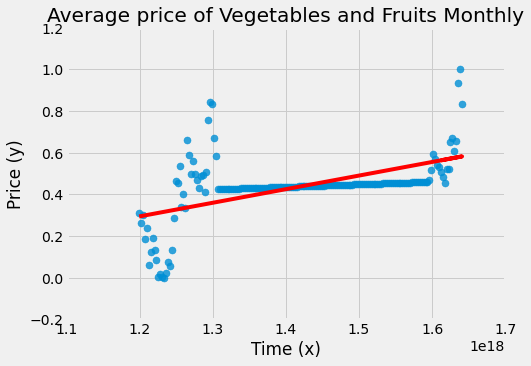

In [44]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DVFM_linreg.coef_ * X + DVFM_linreg.intercept_, 'r-')
plt.title('Average price of Vegetables and Fruits Monthly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [45]:
DVFM_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='MS').to_pydatetime().tolist(), columns=['date'])
DVFM_linear_predict['time'] = DVFM_linear_predict['date'].apply(lambda x: x.value)
DVFM_linear_predict

,date,time
0,2009-01-01,1230768000000000000
1,2009-02-01,1233446400000000000
2,2009-03-01,1235865600000000000
3,2009-04-01,1238544000000000000
4,2009-05-01,1241136000000000000
...,...,...
188,2024-09-01,1725148800000000000
189,2024-10-01,1727740800000000000
190,2024-11-01,1730419200000000000
191,2024-12-01,1733011200000000000


In [46]:
time_predict = np.array(DVFM_linear_predict['time']).reshape((-1, 1))
DVFM_linear_predict['price'] = DVFM_linreg.predict(time_predict)
DVFM_linear_predict

,date,time,price
0,2009-01-01,1230768000000000000,0.314382
1,2009-02-01,1233446400000000000,0.316129
2,2009-03-01,1235865600000000000,0.317708
3,2009-04-01,1238544000000000000,0.319456
4,2009-05-01,1241136000000000000,0.321147
...,...,...,...
188,2024-09-01,1725148800000000000,0.636975
189,2024-10-01,1727740800000000000,0.638667
190,2024-11-01,1730419200000000000,0.640414
191,2024-12-01,1733011200000000000,0.642106


In [47]:
DVFM_linear_normalized_predict = DVFM_linear_predict.copy()
DVFM_linear_normalized_predict = DVFM_linear_normalized_predict[['date', 'price']]
DVFM_linear_normalized_predict.set_index('date', inplace=True)
DVFM_linear_normalized_predict

,price
date,
2009-01-01,0.314382
2009-02-01,0.316129
2009-03-01,0.317708
2009-04-01,0.319456
2009-05-01,0.321147
...,...
2024-09-01,0.636975
2024-10-01,0.638667
2024-11-01,0.640414


##### Unnormalized the data

In [48]:
DVFM_pred_act_linear = scaler.inverse_transform(DVFM_linear_normalized_predict)
DVFM_pred_act_linear_df = pd.DataFrame(DVFM_pred_act_linear)
DVFM_pred_act_linear_df['date'] = DVFM_linear_predict['date']
DVFM_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DVFM_pred_act_linear_df.set_index('date', inplace=True)
DVFM_pred_act_linear_df

,Predicted Price (KG)
date,
2009-01-01,864.167026
2009-02-01,866.459950
2009-03-01,868.530979
2009-04-01,870.823903
2009-05-01,873.042863
...,...
2024-09-01,1287.396514
2024-10-01,1289.615474
2024-11-01,1291.908398
